## DS4200 Project
#### Data Exploration

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
DATA_PATH = '../data/PEERING_DB_CONN_DATA_CENT_WIDEF.csv'
data = pd.read_csv(DATA_PATH)
print(data.shape)
data.head(50)

(203, 19)


,FREQ,FREQ_LABEL,REF_AREA,REF_AREA_LABEL,INDICATOR,INDICATOR_LABEL,UNIT_MEASURE,UNIT_MEASURE_LABEL,AGG_METHOD,AGG_METHOD_LABEL,DATABASE_ID,DATABASE_ID_LABEL,UNIT_MULT,UNIT_MULT_LABEL,OBS_STATUS,OBS_STATUS_LABEL,OBS_CONF,OBS_CONF_LABEL,2023
0,A,Annual,AFE,Africa Eastern and Southern,PEERING_DB_CONN_DATA_CENT,Number of connected data centers (PeeringDB),DC,Data centers,SUM,Sum,PEERING_DB,"Interconnection Database, Number of Connected ...",0,Units,A,Normal value,PU,Public,110
1,A,Annual,AFW,Africa Western and Central,PEERING_DB_CONN_DATA_CENT,Number of connected data centers (PeeringDB),DC,Data centers,SUM,Sum,PEERING_DB,"Interconnection Database, Number of Connected ...",0,Units,A,Normal value,PU,Public,59
2,A,Annual,AGO,Angola,PEERING_DB_CONN_DATA_CENT,Number of connected data centers (PeeringDB),DC,Data centers,SUM,Sum,PEERING_DB,"Interconnection Database, Number of Connected ...",0,Units,A,Normal value,PU,Public,8
3,A,Annual,ALB,Albania,PEERING_DB_CONN_DATA_CENT,Number of connected data centers (PeeringDB),DC,Data centers,SUM,Sum,PEERING_DB,"Interconnection Database, Number of Connected ...",0,Units,A,Normal value,PU,Public,6
4,A,Annual,ARB,Arab World,PEERING_DB_CONN_DATA_CENT,Number of connected data centers (PeeringDB),DC,Data centers,SUM,Sum,PEERING_DB,"Interconnection Database, Number of Connected ...",0,Units,A,Normal value,PU,Public,93
5,A,Annual,ARE,United Arab Emirates,PEERING_DB_CONN_DATA_CENT,Number of connected data centers (PeeringDB),DC,Data centers,SUM,Sum,PEERING_DB,"Interconnection Database, Number of Connected ...",0,Units,A,Normal value,PU,Public,15
6,A,Annual,ARG,Argentina,PEERING_DB_CONN_DATA_CENT,Number of connected data centers (PeeringDB),DC,Data centers,SUM,Sum,PEERING_DB,"Interconnection Database, Number of Connected ...",0,Units,A,Normal value,PU,Public,69
7,A,Annual,ARM,Armenia,PEERING_DB_CONN_DATA_CENT,Number of connected data centers (PeeringDB),DC,Data centers,SUM,Sum,PEERING_DB,"Interconnection Database, Number of Connected ...",0,Units,A,Normal value,PU,Public,9
8,A,Annual,ATG,Antigua and Barbuda,PEERING_DB_CONN_DATA_CENT,Number of connected data centers (PeeringDB),DC,Data centers,SUM,Sum,PEERING_DB,"Interconnection Database, Number of Connected ...",0,Units,A,Normal value,PU,Public,1
9,A,Annual,AUS,Australia,PEERING_DB_CONN_DATA_CENT,Number of connected data centers (PeeringDB),DC,Data centers,SUM,Sum,PEERING_DB,"Interconnection Database, Number of Connected ...",0,Units,A,Normal value,PU,Public,161


In [3]:
#ordering data subset for plot 1
df_bar = data[['REF_AREA_LABEL', '2023']]
df_bar = df_bar[df_bar["REF_AREA_LABEL"] != "World"]
df_bar = df_bar.sort_values(by='2023', ascending=False)
df_bar = df_bar.head(20)
df_bar

,REF_AREA_LABEL,2023
71,High income,4161
139,OECD members,3891
153,Post-demographic dividend,3740
49,Europe & Central Asia,2101
78,IDA & IBRD total,1958
77,IBRD only,1730
108,Low & middle income,1615
121,Middle income,1573
131,North America,1539
56,European Union,1432


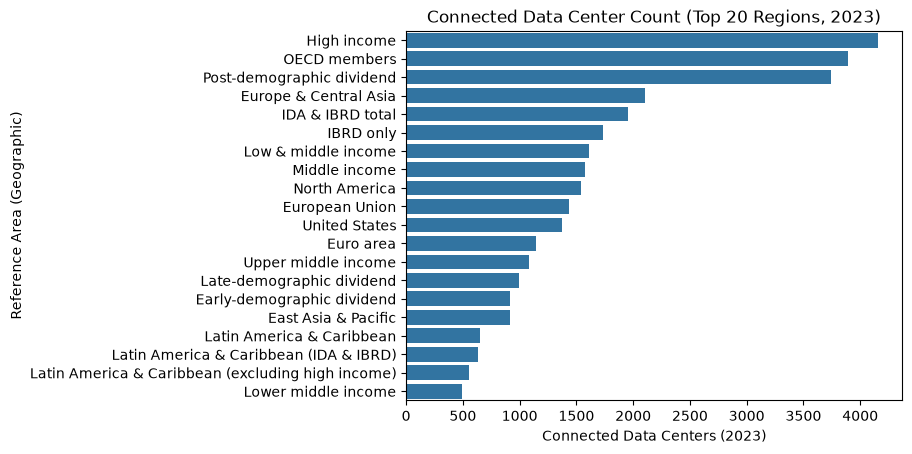

In [4]:
sns.barplot(data=df_bar, x='2023', y='REF_AREA_LABEL')
plt.title("Connected Data Center Count (Top 20 Regions, 2023)")
plt.ylabel("Reference Area (Geographic)")
plt.xlabel("Connected Data Centers (2023)")
plt.show()

In [5]:
# api capture
import requests
import json
import time

api_data = []
counter = 1
while True:
    url = f"https://www.peeringdb.com/api/net/{counter}"
    response = requests.get(url)
    #print(response.text)
    #print(response.get("data", {})[0].get("org", {}))
    if response.status_code == 200:
        response = response.json()
        netixlan_set = response.get("data", {})[0].get("netixlan_set", {})
        #print(response.get("data", {})[0].get("netixlan_set", {}))
        for i in range(len(netixlan_set)):
             api_data.append(netixlan_set[i])
        #api_data.update(response.get("data", {})[0].get("netixlan_set", {}))
        counter += 1
        print(f"Data Collected for {url}")
        time.sleep(15)
    else:
        print(response.text)
        print(f"Error: Request failed for {url} \n Skipping URL")
        counter += 1

    if counter == 6:
        break

Data Collected for https://www.peeringdb.com/api/net/1
Data Collected for https://www.peeringdb.com/api/net/2
Data Collected for https://www.peeringdb.com/api/net/3


KeyboardInterrupt: 

In [ ]:
api_df = pd.DataFrame(api_data)

In [ ]:
api_df

In [ ]:
import requests
import pandas as pd

url = "https://www.peeringdb.com/api/netixlan"

api_data = []

for offset in range(0, 2500, 250):
    response = requests.get(
        url,
        params={
            "limit": 250,
            "skip": offset,
            "status": "ok"
        },
        timeout=30
    )
    response.raise_for_status()

    batch = response.json()["data"]

    if not batch:
        break

    api_data.extend(batch)

api_df = pd.DataFrame(api_data)

print(api_df.shape)

In [ ]:
api_df

In [6]:
import requests
import pandas as pd
import time
import random
import os
from datetime import datetime, timezone
from email.utils import parsedate_to_datetime


def retry_after_seconds(response):
    """Parse Retry-After as seconds or an HTTP date."""
    value = response.headers.get("Retry-After")

    if not value:
        return None

    try:
        return max(0, float(value))
    except ValueError:
        try:
            retry_date = parsedate_to_datetime(value)
            if retry_date.tzinfo is None:
                retry_date = retry_date.replace(tzinfo=timezone.utc)
            return max(
                0,
                (retry_date - datetime.now(timezone.utc)).total_seconds()
            )
        except (ValueError, TypeError, OverflowError):
            return None


def fetch_peeringdb(
    endpoint,
    limit=250,
    max_rows=10000,
    max_retries=5,
    delay=2,
    max_wait=120,
    api_key=None
):
    """
    Fetch PeeringDB data with:
    - Pagination
    - Exponential backoff
    - HTTP 429 handling
    - Network/timeout retries
    - Authentication error handling
    - Partial-result preservation
    """

    records = []
    offset = 0

    session = requests.Session()
    session.headers.update({
        "Accept": "application/json",
        "User-Agent": "AcademicVisualizationProject/1.0"
    })

    api_key = api_key or os.getenv("PEERINGDB_API_KEY")

    if api_key:
        session.headers["Authorization"] = f"Api-Key {api_key}"

    url = f"https://www.peeringdb.com/api/{endpoint}"

    try:
        while offset < max_rows:

            page_limit = min(limit, max_rows - offset)

            params = {
                "limit": page_limit,
                "skip": offset,
                "status": "ok"
            }

            success = False

            for attempt in range(max_retries + 1):

                try:
                    response = session.get(
                        url,
                        params=params,
                        timeout=30
                    )

                    # Rate limited
                    if response.status_code == 429:
                        if attempt == max_retries:
                            print(
                                f"Rate limit persisted after "
                                f"{max_retries + 1} attempts."
                            )
                            break

                        server_wait = retry_after_seconds(response)

                        if server_wait is not None:
                            wait = server_wait
                        else:
                            wait = min(
                                max_wait,
                                5 * (2 ** attempt) + random.uniform(0, 2)
                            )

                        # Avoid silently waiting excessively
                        if wait > max_wait:
                            print(
                                f"Server requested {wait:.1f}s wait; "
                                "stopping this download."
                            )
                            break

                        print(
                            f"429: Rate limited. "
                            f"Retrying in {wait:.1f}s "
                            f"(attempt {attempt + 1}/{max_retries})"
                        )

                        time.sleep(wait)
                        continue

                    # Authentication or permission failures
                    if response.status_code in (401, 403):
                        print(
                            f"Access refused ({response.status_code}). "
                            "Check API credentials or permissions."
                        )
                        break

                    # Other temporary server failures
                    if response.status_code in (500, 502, 503, 504):
                        if attempt == max_retries:
                            break

                        wait = retry_after_seconds(response)

                        if wait is None:
                            wait = min(
                                max_wait,
                                2 ** attempt + random.uniform(0, 2)
                            )

                        if wait > max_wait:
                            break

                        print(
                            f"Server error {response.status_code}. "
                            f"Retrying in {wait:.1f}s."
                        )

                        time.sleep(wait)
                        continue

                    # Other HTTP errors should not be retried
                    response.raise_for_status()

                    payload = response.json()
                    batch = payload.get("data")

                    if not isinstance(batch, list):
                        raise ValueError(
                            "Unexpected API response: "
                            "'data' is missing or is not a list."
                        )

                    records.extend(batch)
                    offset += len(batch)

                    print(
                        f"[{endpoint}] Fetched {len(batch)} rows | "
                        f"Total: {len(records)}"
                    )

                    success = True
                    break

                except (
                    requests.exceptions.Timeout,
                    requests.exceptions.ConnectionError
                ) as e:
                    if attempt == max_retries:
                        print(f"Network failure: {e}")
                        break

                    wait = min(
                        max_wait,
                        2 ** attempt + random.uniform(0, 2)
                    )

                    print(
                        f"Connection issue. Retrying in {wait:.1f}s."
                    )
                    time.sleep(wait)

                except (
                    requests.exceptions.HTTPError,
                    requests.exceptions.JSONDecodeError,
                    ValueError
                ) as e:
                    print(f"Request failed: {e}")
                    break

            if not success:
                print(
                    f"Stopped at offset {offset}. "
                    f"Preserved {len(records)} previously fetched rows."
                )
                break

            # End of available data
            if len(batch) < page_limit:
                print(f"[{endpoint}] End of dataset reached.")
                break

            # Polite delay between successful requests
            if offset < max_rows:
                time.sleep(delay + random.uniform(0, 0.5))

    finally:
        session.close()

    df = pd.DataFrame(records)

    if "id" in df.columns:
        df = df.drop_duplicates(subset="id")

    print(f"\nFinished {endpoint}: {df.shape}")

    return df

## Net: Information on individual networks

In [7]:
net_df = fetch_peeringdb(
    "net",
    limit=250,
    max_rows=10000,
    delay=3
)

[net] Fetched 250 rows | Total: 250
[net] Fetched 250 rows | Total: 500
[net] Fetched 250 rows | Total: 750
[net] Fetched 250 rows | Total: 1000
[net] Fetched 250 rows | Total: 1250
[net] Fetched 250 rows | Total: 1500
[net] Fetched 250 rows | Total: 1750
[net] Fetched 250 rows | Total: 2000
[net] Fetched 250 rows | Total: 2250
[net] Fetched 250 rows | Total: 2500
[net] Fetched 250 rows | Total: 2750
[net] Fetched 250 rows | Total: 3000
[net] Fetched 250 rows | Total: 3250
[net] Fetched 250 rows | Total: 3500
[net] Fetched 250 rows | Total: 3750
[net] Fetched 250 rows | Total: 4000
[net] Fetched 250 rows | Total: 4250
[net] Fetched 250 rows | Total: 4500
[net] Fetched 250 rows | Total: 4750
[net] Fetched 250 rows | Total: 5000
[net] Fetched 250 rows | Total: 5250
[net] Fetched 250 rows | Total: 5500
[net] Fetched 250 rows | Total: 5750
[net] Fetched 250 rows | Total: 6000
[net] Fetched 250 rows | Total: 6250
[net] Fetched 250 rows | Total: 6500
[net] Fetched 250 rows | Total: 6750
[net

In [ ]:
net_df.head()

## IX: Internet Exchange Point (IEP) registry of facilities, networks, and participant Autonomous Systems 

In [8]:
ix_df = fetch_peeringdb(
    "ix",
    limit=250,
    max_rows=10000,
    delay=3
)

[ix] Fetched 250 rows | Total: 250
[ix] Fetched 250 rows | Total: 500
[ix] Fetched 250 rows | Total: 750
[ix] Fetched 250 rows | Total: 1000
[ix] Fetched 250 rows | Total: 1250
[ix] Fetched 82 rows | Total: 1332
[ix] End of dataset reached.

Finished ix: (1332, 35)


In [9]:
ix_df.head()

,id,org_id,name,aka,name_long,city,country,region_continent,media,notes,...,ixf_last_import,ixf_import_request,ixf_import_request_status,service_level,terms,status_dashboard,logo,created,updated,status
0,1,2,Equinix Ashburn,,Equinix Internet Exchange Ashburn,Ashburn,US,North America,Ethernet,,...,NaN,NaN,queued,24/7 Support,Recurring Fees,,NaN,2010-07-29T00:00:00Z,2024-07-26T15:34:35Z,ok
1,2,2,Equinix Chicago,,Equinix Internet Exchange Chicago,Chicago,US,North America,Ethernet,,...,NaN,NaN,queued,24/7 Support,Recurring Fees,,NaN,2010-07-29T00:00:00Z,2024-07-26T15:35:01Z,ok
2,3,2,Equinix Dallas,,Equinix Internet Exchange Dallas,Dallas,US,North America,Ethernet,,...,NaN,NaN,queued,24/7 Support,Recurring Fees,,NaN,2010-07-29T00:00:00Z,2024-07-26T15:35:07Z,ok
3,4,2,Equinix Los Angeles,,Equinix Internet Exchange Los Angeles,Los Angeles,US,North America,Ethernet,,...,NaN,NaN,queued,24/7 Support,Recurring Fees,,NaN,2010-07-29T00:00:00Z,2024-07-26T15:36:49Z,ok
4,5,2,Equinix San Jose,,Equinix Internet Exchange San Jose (Bay Area),San Jose,US,North America,Ethernet,,...,NaN,NaN,queued,24/7 Support,Recurring Fees,,NaN,2010-07-29T00:00:00Z,2024-07-26T15:38:33Z,ok


## Netixlan: Network Internet Exchange - Mapping between network (net) and exchange points (ix)

In [10]:
netixlan_df = fetch_peeringdb(
    "netixlan",
    limit=250,
    max_rows=20000,
    delay=3
)

[netixlan] Fetched 250 rows | Total: 250
[netixlan] Fetched 250 rows | Total: 500
[netixlan] Fetched 250 rows | Total: 750
[netixlan] Fetched 250 rows | Total: 1000
[netixlan] Fetched 250 rows | Total: 1250
[netixlan] Fetched 250 rows | Total: 1500
[netixlan] Fetched 250 rows | Total: 1750
[netixlan] Fetched 250 rows | Total: 2000
[netixlan] Fetched 250 rows | Total: 2250
[netixlan] Fetched 250 rows | Total: 2500
[netixlan] Fetched 250 rows | Total: 2750
[netixlan] Fetched 250 rows | Total: 3000
[netixlan] Fetched 250 rows | Total: 3250
[netixlan] Fetched 250 rows | Total: 3500
[netixlan] Fetched 250 rows | Total: 3750
[netixlan] Fetched 250 rows | Total: 4000
[netixlan] Fetched 250 rows | Total: 4250
[netixlan] Fetched 250 rows | Total: 4500
[netixlan] Fetched 250 rows | Total: 4750
[netixlan] Fetched 250 rows | Total: 5000
[netixlan] Fetched 250 rows | Total: 5250
[netixlan] Fetched 250 rows | Total: 5500
[netixlan] Fetched 250 rows | Total: 5750
[netixlan] Fetched 250 rows | Total: 

### Plots

In [ ]:
net_df.columns

In [ ]:
ix_df.columns

In [ ]:
netixlan_df.columns

In [ ]:
plot1 = net_df[["ix_count", "fac_count", "info_type"]]
#plot1 = plot1.groupby("info_type")["fac_count"].mean()
plot1

In [ ]:
sns.swarmplot(data=plot1, x="ix_count", y="info_type", size=0.1)

Task was destroyed but it is pending!
task: <Task pending name='Task-184' coro=<_async_in_context.<locals>.run_in_context() done, defined at /Users/seamuscoyne/anaconda3/envs/ds4200/lib/python3.11/site-packages/ipykernel/utils.py:57> wait_for=<Task pending name='Task-185' coro=<Kernel.shell_main() running at /Users/seamuscoyne/anaconda3/envs/ds4200/lib/python3.11/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at /Users/seamuscoyne/anaconda3/envs/ds4200/lib/python3.11/site-packages/zmq/eventloop/zmqstream.py:564]>
/Users/seamuscoyne/anaconda3/envs/ds4200/lib/python3.11/json/decoder.py:353: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  obj, end = self.scan_once(s, idx)
Task was destroyed but it is pending!
task: <Task pending name='Task-185' coro=<Kernel.shell_main() running at /Users/seamuscoyne/anaconda3/envs/ds4200/lib/python3.11/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]

not starting a machine. unresolved inputs: <dynamic input>
kept this cell on this machine


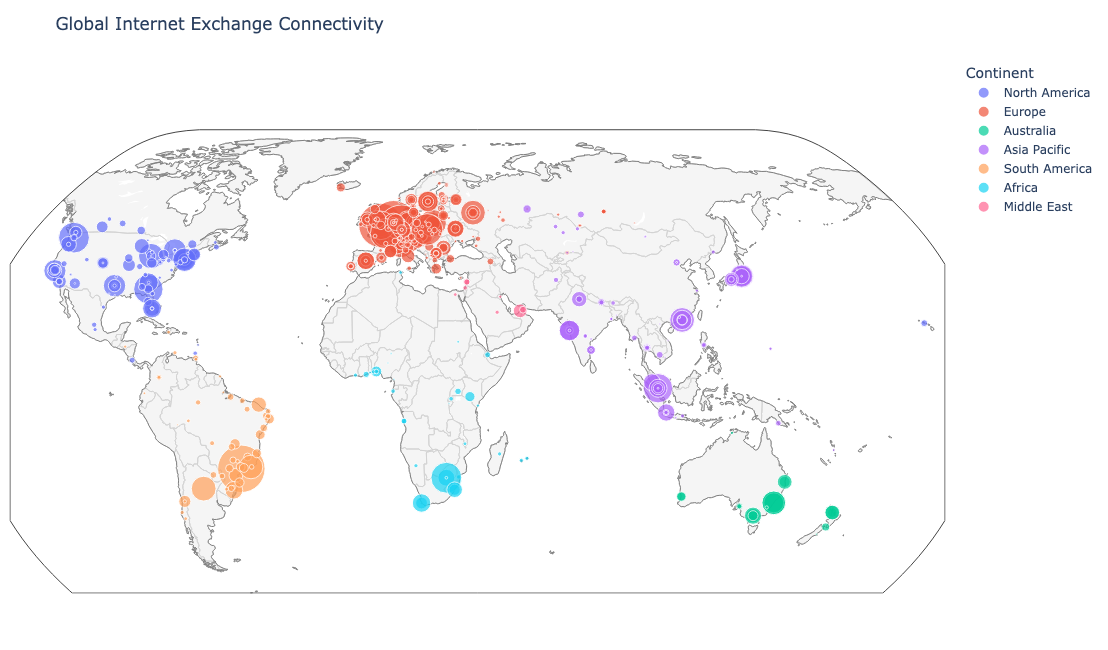

In [14]:
import pandas as pd
import numpy as np
import plotly.express as px
import pycountry
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter
from pathlib import Path

# 1. Aggregate network participation per exchange
connections = (
    netixlan_df
    .query("status == 'ok'")
    .groupby("ix_id")
    .agg(
        network_count=("asn", "nunique"),
        total_speed=("speed", "sum")
    )
    .reset_index()
)

# 2. Merge exchange metadata
ix_map = (
    ix_df
    .query("status == 'ok'")
    [["id", "name", "city", "country", "region_continent"]]
    .merge(
        connections,
        left_on="id",
        right_on="ix_id",
        how="left"
    )
)

ix_map["network_count"] = ix_map["network_count"].fillna(0)
ix_map["total_speed"] = ix_map["total_speed"].fillna(0)

# 3. Geocode unique city/country pairs
cache_path = Path("peeringdb_geocodes.csv")

if cache_path.exists():
    geo_cache = pd.read_csv(cache_path)
else:
    geo_cache = pd.DataFrame(
        columns=["city", "country", "lat", "lon"]
    )

geolocator = Nominatim(user_agent="peeringdb_ds4200")
geocode = RateLimiter(
    geolocator.geocode,
    min_delay_seconds=1.1,
    max_retries=2
)

locations = (
    ix_map[["city", "country"]]
    .dropna()
    .drop_duplicates()
)

# Only geocode locations not already cached
pending = locations.merge(
    geo_cache[["city", "country"]],
    on=["city", "country"],
    how="left",
    indicator=True
)

pending = pending[pending["_merge"] == "left_only"]

new_locations = []

for _, row in pending.iterrows():
    city = row["city"]
    country = row["country"]

    # Translate ISO country code to country name
    country_obj = pycountry.countries.get(alpha_2=country)
    country_name = country_obj.name if country_obj else country

    try:
        location = geocode(f"{city}, {country_name}")

        new_locations.append({
            "city": city,
            "country": country,
            "lat": location.latitude if location else np.nan,
            "lon": location.longitude if location else np.nan
        })

    except Exception as e:
        print(f"Geocoding failed for {city}, {country}: {e}")

    # Save incremental progress
    if len(new_locations) >= 25:
        geo_cache = pd.concat(
            [geo_cache, pd.DataFrame(new_locations)],
            ignore_index=True
        )
        geo_cache.to_csv(cache_path, index=False)
        new_locations = []

if new_locations:
    geo_cache = pd.concat(
        [geo_cache, pd.DataFrame(new_locations)],
        ignore_index=True
    )
    geo_cache.to_csv(cache_path, index=False)

# 4. Attach coordinates
ix_map = ix_map.merge(
    geo_cache,
    on=["city", "country"],
    how="left"
)

ix_map = ix_map.dropna(subset=["lat", "lon"])

# Optional: remove exchanges without observed connections
ix_map = ix_map[ix_map["network_count"] > 0].copy()

# 5. Interactive bubble map
fig = px.scatter_geo(
    ix_map,
    lat="lat",
    lon="lon",
    size="network_count",
    color="region_continent",
    hover_name="name",
    hover_data={
        "city": True,
        "country": True,
        "network_count": ":,",
        "total_speed": ":,",
        "lat": False,
        "lon": False,
        "region_continent": False
    },
    size_max=35,
    projection="natural earth",
    title="Global Internet Exchange Connectivity"
)

fig.update_geos(
    showcountries=True,
    countrycolor="lightgray",
    showcoastlines=True,
    coastlinecolor="gray",
    showland=True,
    landcolor="#F5F5F5"
)

fig.update_layout(
    height=650,
    margin=dict(l=10, r=10, t=60, b=10),
    legend_title_text="Continent"
)

fig.show()